# Signal peptide: CNN one-hot + Optuna + test finale

Pipeline: **1)** dati → **2)** modello → **3)** Optuna (CV sui fold ≥ 0) → **4)** riallenamento su tutti i fold ≥ 0 → **5)** test sul fold `-1` (una volta sola).

Cosa modificare prima di lanciare: la cella **Configurazione** (path dei dati e flag).

## 0. Configurazione

In [1]:
import os, json, random
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import TensorDataset, DataLoader, Subset

#!pip install optuna      
import optuna

# --------------------------------
FASTA_PATH = '/kaggle/input/datasets/alixram/signalpep/merged.fasta'
TSV_PATH   = "/kaggle/input/datasets/alixram/signalpep/Cleaned_merged_dataset.tsv"
OUT_DIR    = "/kaggle/working"     

MAX_LEN    = 120
N_TRIALS   = 40                    # per un test veloce metti 2
RUN_OPTUNA = True
RUN_FINAL  = True                 # metti True SOLO quando Optuna e' finito: tocca il fold -1
N_SEEDS    = 1                    #numero medelli ensemble
# -----------------------------------------------

os.makedirs(OUT_DIR, exist_ok=True)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("device:", device)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(s)

device: cuda


## 1. Dati

In [2]:
AMINO_ACIDS = "ACDEFGHIKLMNPQRSTVWY"
AA_TO_IDX = {aa: i for i, aa in enumerate(AMINO_ACIDS)}

In [3]:
def read_fasta(path):
    seqs, cur_id, buf = {}, None, []
    with open(path) as f:
        for line in f:
            line = line.strip()
            if not line:
                continue
            if line.startswith(">"):
                if cur_id is not None:
                    seqs[cur_id] = "".join(buf)
                cur_id = line[1:].split()[0]      # toglie '>' e spazi finali
                buf = []                          # serve per le seq su piu' righe
            else:
                buf.append(line)

        # scrivo anche l'ultima seq
        if cur_id is not None:
            seqs[cur_id] = "".join(buf)
    return seqs

In [4]:
def build_dataset(fasta_path, tsv_path, max_len=120):
    seqs = read_fasta(fasta_path)
    meta = pd.read_csv(tsv_path, sep="\t").set_index("ID")

    # includo solo seq per cui ho un id sia nel meta che nel fasta
    ids = [i for i in seqs if i in meta.index]
    N = len(ids)

    # inizializzo a zero per il padding
    X = torch.zeros(N, max_len, 20)                       # matrice one-hot
    pad_start = torch.zeros(N, dtype=torch.long)          # lunghezze reali
    fold = torch.tensor(meta.loc[ids, "fold"].values, dtype=torch.long)
    labels = torch.tensor(meta.loc[ids, "class"].values, dtype=torch.long)

    # one-hot encoding
    for n, id in enumerate(ids):
        idx = [AA_TO_IDX[aa] for aa in seqs[id] if aa in AA_TO_IDX][:max_len]
        idx = torch.tensor(idx, dtype=torch.long)
        X[n, torch.arange(len(idx)), idx] = 1.0
        pad_start[n] = len(idx)

    print(f"{N} sequenze, {len(seqs) - N} scartate (ID assenti nel TSV)")
    return TensorDataset(X, pad_start, fold, labels), ids

In [5]:
dataset, ids = build_dataset(FASTA_PATH, TSV_PATH, max_len=MAX_LEN)
X, pad_start, fold, labels = dataset.tensors
print(X.shape, pad_start.shape, fold.shape, labels.shape)
print("classi:", labels.unique(return_counts=True))
print("fold:  ", fold.unique(return_counts=True))

9728 sequenze, 0 scartate (ID assenti nel TSV)
torch.Size([9728, 120, 20]) torch.Size([9728]) torch.Size([9728]) torch.Size([9728])
classi: (tensor([0, 1]), tensor([8624, 1104]))
fold:   (tensor([-1,  1,  2,  3,  4,  5]), tensor([1946, 1557, 1557, 1556, 1556, 1556]))


In [6]:
def get_loaders(dataset, val_fold, batch_size=64):

    fold = dataset.tensors[2]  # vettore fold

    # esclude il fold di validazione e il -1 (benchmark);
    # [0] perche' where ritorna una tupla es: (tensor([4]),)
    train_idx = torch.where((fold != val_fold) & (fold >= 0))[0]
    val_idx   = torch.where(fold == val_fold)[0]

    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=batch_size, shuffle=True)
    val_loader   = DataLoader(Subset(dataset, val_idx),   batch_size=batch_size)

    return train_loader, val_loader

## 2. Modello

1. **Input**: ogni sequenza è `(L, 20)`; in `forward` si traspone in `(20, L)` perché `Conv1d` vuole `(batch, canali, lunghezza)`. I canali sono i 20 aminoacidi, quindi `ch_in = 20`.
2. **Convoluzione**: un filtro `(20 × k)` scorre lungo la sequenza e dà un numero alto dove la finestra di `k` residui somiglia al suo pattern (come una PWM imparata). `ch_out` filtri = `ch_out` rilevatori di motivi.
3. **ReLU** tiene i motivi trovati, **LayerNorm** stabilizza le scale tra canali, **Dropout** evita che la rete dipenda da pochi filtri.
4. **MultiKernelBlock**: più convoluzioni in parallelo (k = 3, 5, 9...) concatenate sui canali, così la rete sceglie la scala utile.
5. **MaxPool(2)** dimezza la lunghezza e allarga il campo visivo del blocco successivo.
6. **Secondo blocco**: lavora sui motivi del primo, quindi riconosce combinazioni (es. regione positiva seguita da regione idrofobica).
7. **Global pooling mascherato (max + mean)**: il max dice "c'è il motivo da qualche parte?", la media "quanto è diffuso?". La maschera esclude il padding.

In [7]:
class ConvBlock(nn.Module):
    """Conv1d -> ReLU -> LayerNorm (sui canali) -> Dropout1d"""
    def __init__(self, ch_in, ch_out, kernel_size=9, p=0.3):
        super().__init__()
        self.conv = nn.Conv1d(ch_in, ch_out, kernel_size, padding=kernel_size // 2)
        self.norm = nn.LayerNorm(ch_out)
        self.drop = nn.Dropout1d(p)

    def forward(self, x):                                   # x: (B, C, L)
        x = F.relu(self.conv(x))
        x = self.norm(x.transpose(1, 2)).transpose(1, 2)    # LayerNorm vuole i canali per ultimi
        return self.drop(x)


class MultiKernelBlock(nn.Module):
    """Conv1d in parallelo con kernel diversi -> concat -> ReLU -> LayerNorm -> Dropout1d"""
    def __init__(self, ch_in, ch_branch, kernel_sizes=(3, 5, 9), p=0.3):
        super().__init__()
        assert all(k % 2 == 1 for k in kernel_sizes), "kernel dispari, altrimenti le lunghezze non coincidono"
        self.convs = nn.ModuleList([
            nn.Conv1d(ch_in, ch_branch, k, padding=k // 2) for k in kernel_sizes
        ])
        ch_out = ch_branch * len(kernel_sizes)
        self.norm = nn.LayerNorm(ch_out)
        self.drop = nn.Dropout1d(p)

    def forward(self, x):                                   # x: (B, C, L)
        x = torch.cat([conv(x) for conv in self.convs], dim=1)   # (B, ch_branch*n_k, L)
        x = F.relu(x)
        x = self.norm(x.transpose(1, 2)).transpose(1, 2)
        return self.drop(x)

In [8]:
class SigCNN(nn.Module):
    def __init__(self, ch_in=20, ch_branch=24, kernel_sizes=(3, 5, 9), ch_hid2=32,
                 kernel2=9, p=0.3, n_classes=1, head_hid=64):
        super().__init__()
        ch_mid = ch_branch * len(kernel_sizes)

        self.block1 = MultiKernelBlock(ch_in, ch_branch, kernel_sizes, p)
        self.block2 = ConvBlock(ch_mid, ch_hid2, kernel2, p)
        self.pool = nn.MaxPool1d(2)

        self.head = nn.Sequential(
            nn.Linear(2 * ch_hid2, head_hid),               # max + mean
            nn.ReLU(),
            nn.Dropout(p),
            nn.Linear(head_hid, n_classes),
        )

    def forward(self, x, lengths):
        # x: (B, L, 20) one-hot, lengths: (B,) = pad_start
        x = x.transpose(1, 2)                               # (B, 20, L)
        L = x.size(-1)
        mask = (torch.arange(L, device=x.device)[None, :] < lengths[:, None]).float().unsqueeze(1)  # (B,1,L)

        x = self.pool(self.block1(x) * mask)                # azzero il padding
        mask = self.pool(mask)
        x = self.pool(self.block2(x) * mask)                # azzero il padding
        mask = self.pool(mask)

        # global pool mascherato (ignora il padding)
        x_max = x.masked_fill(mask == 0, float("-inf")).max(dim=-1).values
        x_mean = (x * mask).sum(-1) / mask.sum(-1).clamp(min=1)
        x = torch.cat([x_max, x_mean], dim=1)               # (B, 2*ch_hid2)

        return self.head(x)

In [9]:
# controllo rapido: forma dell'output e numero di parametri
train_loader, val_loader = get_loaders(dataset, val_fold=1)
m = SigCNN().to(device)
xb, lens, _, yb = next(iter(train_loader))
print("logits:", m(xb.to(device), lens.to(device)).shape)
print("parametri:", sum(p.numel() for p in m.parameters()))
del m

logits: torch.Size([64, 1])
parametri: 33433


## 3. Training di un fold + Optuna

In [10]:
from sklearn.metrics import matthews_corrcoef

def train_one_fold(model, train_loader, val_loader, lr, wd, max_epochs=40, patience=6,
                   return_history=False):

    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss()
    best_mcc, best_ep, bad = -1.0, 0, 0
    hist = []

    for ep in range(max_epochs):
        model.train()
        train_losses = []
        for xb, lens, _, yb in train_loader:

            # sposto tutto su gpu
            xb, lens, yb = xb.to(device), lens.to(device), yb.float().to(device)

            # azzero gradiente
            opt.zero_grad()

            # loss_fn(y_pred, y_true)
            loss = loss_fn(model(xb, lens).squeeze(1), yb)

            # backward: calcolo i gradienti
            loss.backward()

            # aggiorno ogni parametro con requires_grad=True
            opt.step()

            train_losses.append(loss.item())

        # eval mode (disattiva dropout)
        model.eval()

        # a fine epoca valuto sulla validation
        preds, ys = [], []
        val_losses = []
        with torch.no_grad():
            for xb, lens, _, yb in val_loader:
                logits = model(xb.to(device), lens.to(device)).squeeze(1)
                val_losses.append(loss_fn(logits, yb.float().to(device)).item())
                preds.append((logits > 0).long().cpu())
                ys.append(yb)
        mcc = matthews_corrcoef(torch.cat(ys).numpy(), torch.cat(preds).numpy())

        hist.append(dict(epoch=ep + 1, train_loss=np.mean(train_losses),
                         val_loss=np.mean(val_losses), val_mcc=mcc))

        if mcc > best_mcc:
            best_mcc, best_ep, bad = mcc, ep + 1, 0
        else:
            bad += 1
            if bad >= patience:       # early stopping
                break

    if return_history:
        return best_mcc, best_ep, pd.DataFrame(hist)
    return best_mcc, best_ep

In [11]:
folds = [1, 2, 3, 4, 5]     # fold di CV (il -1 e' il benchmark e NON entra qui)

def objective(trial):
    ch_branch = trial.suggest_categorical("ch_branch", [16, 24, 32, 48])
    k_set     = trial.suggest_categorical("kernels", ["3-5-9", "5-9-15", "3-7-11"])
    kernels   = tuple(int(k) for k in k_set.split("-"))
    ch_hid2   = trial.suggest_categorical("ch_hid2", [32, 64])
    p         = trial.suggest_float("p", 0.1, 0.5)
    lr        = trial.suggest_float("lr", 1e-4, 1e-2, log=True)
    wd        = trial.suggest_float("wd", 1e-6, 1e-2, log=True)
    bs        = trial.suggest_categorical("batch_size", [32, 64, 128])

    scores, epochs = [], []
    for i, vf in enumerate(folds):
        set_seed(0)                                   # riproducibilita'
        train_loader, val_loader = get_loaders(dataset, val_fold=vf, batch_size=bs)
        model = SigCNN(ch_branch=ch_branch, kernel_sizes=kernels, ch_hid2=ch_hid2, p=p)
        mcc, ep = train_one_fold(model, train_loader, val_loader, lr, wd)
        scores.append(mcc); epochs.append(ep)

        # pruning: se dopo qualche fold il trial va male, lo fermo
        trial.report(sum(scores) / len(scores), step=i)
        if trial.should_prune():
            raise optuna.TrialPruned()

    trial.set_user_attr("best_epochs", epochs)
    return sum(scores) / len(scores)

In [12]:
study = optuna.create_study(
    study_name="sigcnn",
    storage=f"sqlite:///{OUT_DIR}/study.db",
    load_if_exists=True,                              # se riparti, continua da dove eri
    direction="maximize",                             # MCC alto = meglio
    sampler=optuna.samplers.TPESampler(seed=0),
    pruner=optuna.pruners.MedianPruner(n_startup_trials=5),
)

if RUN_OPTUNA:
    remaining = max(0, N_TRIALS - len(study.trials))
    study.optimize(objective, n_trials=remaining)

print("trial totali:", len(study.trials))
print("best MCC (CV):", study.best_value)
print(study.best_params)

best = study.best_trial
with open(f"{OUT_DIR}/best_params.json", "w") as f:
    json.dump({"params": best.params,
               "best_epochs": best.user_attrs["best_epochs"],
               "cv_mcc": best.value}, f, indent=2)

[I 2026-11-19 18:24:08,050] A new study created in RDB with name: sigcnn
[I 2026-11-19 18:25:00,511] Trial 0 finished with value: 0.8970093896860274 and parameters: {'ch_branch': 24, 'kernels': '5-9-15', 'ch_hid2': 64, 'p': 0.2533766075303111, 'lr': 0.0038322168504927897, 'wd': 0.000130490735503624, 'batch_size': 64}. Best is trial 0 with value: 0.8970093896860274.
[I 2026-11-19 18:26:24,757] Trial 1 finished with value: 0.9139211047576883 and parameters: {'ch_branch': 32, 'kernels': '5-9-15', 'ch_hid2': 64, 'p': 0.1473097703475733, 'lr': 0.001904767808428205, 'wd': 3.7446665357415703e-06, 'batch_size': 32}. Best is trial 1 with value: 0.9139211047576883.
[I 2026-11-19 18:28:07,883] Trial 2 finished with value: 0.9013068363533284 and parameters: {'ch_branch': 24, 'kernels': '5-9-15', 'ch_hid2': 64, 'p': 0.3727281196413934, 'lr': 0.0005236194873419149, 'wd': 5.59922365406335e-05, 'batch_size': 32}. Best is trial 1 with value: 0.9139211047576883.
[I 2026-11-19 18:29:08,826] Trial 3 finis

trial totali: 40
best MCC (CV): 0.9181466982797728
{'ch_branch': 16, 'kernels': '5-9-15', 'ch_hid2': 64, 'p': 0.20738061877978914, 'lr': 0.004987112083132116, 'wd': 1.0139491112569927e-06, 'batch_size': 32}


In [13]:
# quali iperparametri contano di piu'
try:
    print(optuna.importance.get_param_importances(study))
except Exception as e:
    print("importanze non disponibili (servono piu' trial completati):", e)

{'lr': 0.7373896927436729, 'wd': 0.11086312933381684, 'ch_branch': 0.06724828503594535, 'batch_size': 0.030005569332757488, 'p': 0.028992868333317868, 'ch_hid2': 0.013113256729835003, 'kernels': 0.012387198490654517}


### Curve di allenamento (fold di CV, migliori iperparametri)

fold 1: best epoch 13 | MCC 0.9360 | epoche eseguite 19
fold 2: best epoch 10 | MCC 0.9005 | epoche eseguite 16
fold 3: best epoch 7 | MCC 0.8900 | epoche eseguite 13
fold 4: best epoch 16 | MCC 0.9279 | epoche eseguite 22
fold 5: best epoch 5 | MCC 0.9057 | epoche eseguite 11


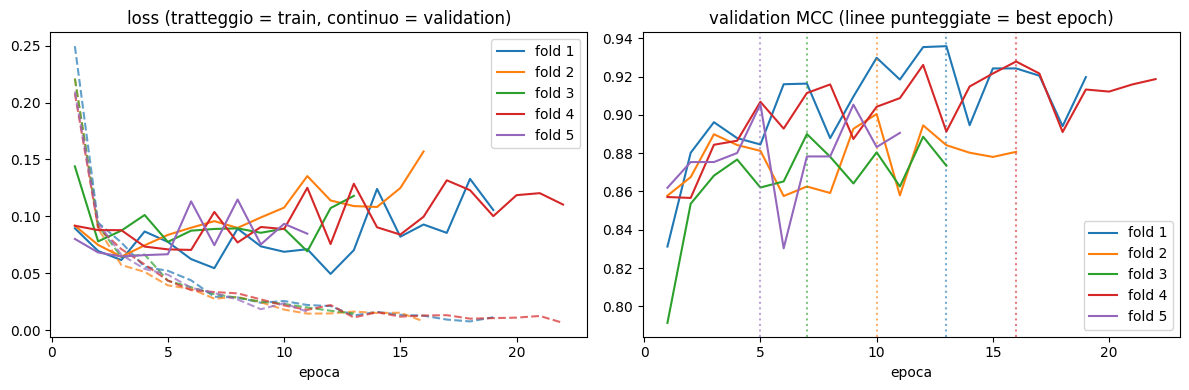

best epoch per fold: [13, 10, 7, 16, 5] | mediana = 10


In [14]:
import matplotlib.pyplot as plt

bp = study.best_params
kernels = tuple(int(k) for k in bp["kernels"].split("-"))

histories = {}
for vf in folds:                                   # solo fold di CV: il -1 NON si tocca
    set_seed(0)
    tr_l, va_l = get_loaders(dataset, val_fold=vf, batch_size=bp["batch_size"])
    model = SigCNN(ch_branch=bp["ch_branch"], kernel_sizes=kernels,
                   ch_hid2=bp["ch_hid2"], p=bp["p"])
    mcc, ep, h = train_one_fold(model, tr_l, va_l, bp["lr"], bp["wd"], return_history=True)
    histories[vf] = (h, ep)
    print(f"fold {vf}: best epoch {ep} | MCC {mcc:.4f} | epoche eseguite {len(h)}")

colors = plt.cm.tab10.colors
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

# (1) loss per fold: train tratteggiata, validation continua
for i, (vf, (h, ep)) in enumerate(histories.items()):
    c = colors[i]
    ax[0].plot(h.epoch, h.train_loss, "--", color=c, alpha=.7)
    ax[0].plot(h.epoch, h.val_loss, "-", color=c, label=f"fold {vf}")
ax[0].set_title("loss (tratteggio = train, continuo = validation)")
ax[0].set_xlabel("epoca")
ax[0].legend()

# (2) MCC di validation per fold, con l'epoca migliore marcata
for i, (vf, (h, ep)) in enumerate(histories.items()):
    c = colors[i]
    ax[1].plot(h.epoch, h.val_mcc, color=c, label=f"fold {vf}")
    ax[1].axvline(ep, color=c, ls=":", alpha=.6)
ax[1].set_title("validation MCC (linee punteggiate = best epoch)")
ax[1].set_xlabel("epoca")
ax[1].legend()

plt.tight_layout()
plt.show()

best_eps = [ep for _, ep in histories.values()]
print(f"best epoch per fold: {best_eps} | mediana = {int(np.median(best_eps))}")

## 4-5. Riallenamento su tutti i fold ≥ 0 e test sul fold `-1`

Questa sezione gira solo con `RUN_FINAL = True` (cella Configurazione). Il benchmark `-1` va guardato **una volta sola**

In [15]:
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix

def train_fixed_epochs(model, loader, lr, wd, n_epochs):
    model = model.to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr, weight_decay=wd)
    loss_fn = nn.BCEWithLogitsLoss()
    for ep in range(n_epochs):
        model.train()
        for xb, lens, _, yb in loader:
            xb, lens, yb = xb.to(device), lens.to(device), yb.float().to(device)
            opt.zero_grad()

            y_pred=model(xb, lens).squeeze(1)

            loss=loss_fn(y_pred, yb)

            loss.backward()

            opt.step()

    return model


def predict_proba(model, loader):
    model.eval()
    probs, ys = [], []
    with torch.no_grad():
        
        for xb, lens, _, yb in loader:
            logits = model(xb.to(device), lens.to(device)).squeeze(1)

            probs.append(torch.sigmoid(logits).cpu())

            ys.append(yb)

    return torch.cat(probs).numpy(), torch.cat(ys).numpy()

In [16]:
if not RUN_FINAL:
    print("RUN_FINAL = False: salto riallenamento e test.")
else:
    completed = [t for t in study.trials if t.state == optuna.trial.TrialState.COMPLETE]
    assert completed, "Nessun trial Optuna completato: esegui prima la ricerca."

    best = study.best_trial
    bp = best.params
    kernels = tuple(int(k) for k in bp["kernels"].split("-"))
    n_ep = max(1, int(np.median(best.user_attrs["best_epochs"])))
    print("iperparametri:", bp)
    print("epoche fisse (mediana CV):", n_ep)

    # train = tutti i fold >= 0, test = fold == -1
    fold = dataset.tensors[2]
    train_idx = torch.where(fold >= 0)[0]
    test_idx  = torch.where(fold == -1)[0]
    print(f"train: {len(train_idx)} seq | test (benchmark): {len(test_idx)} seq")

    train_loader = DataLoader(Subset(dataset, train_idx), batch_size=bp["batch_size"], shuffle=True)
    test_loader  = DataLoader(Subset(dataset, test_idx),  batch_size=bp["batch_size"])

    config = dict(ch_branch=bp["ch_branch"], kernel_sizes=kernels,
                  ch_hid2=bp["ch_hid2"], p=bp["p"])

    all_probs = []
    for seed in range(N_SEEDS):
        set_seed(seed)
        model = SigCNN(**config)
        model = train_fixed_epochs(model, train_loader, bp["lr"], bp["wd"], n_ep)

        torch.save({"state_dict": model.state_dict(), "config": config, "n_epochs": n_ep},
                   f"{OUT_DIR}/sigcnn_final_seed{seed}.pt")

        probs, y_test = predict_proba(model, test_loader)
        all_probs.append(probs)
        print(f"seed {seed}: MCC = {matthews_corrcoef(y_test, (probs > 0.5).astype(int)):.4f}")

    p_ens = np.mean(all_probs, axis=0)
    y_pred = (p_ens > 0.5).astype(int)

    print("\n--- Modello sul benchmark (fold -1) ---")
    print("MCC:   ", matthews_corrcoef(y_test, y_pred))
    print("AUC:   ", roc_auc_score(y_test, p_ens))
    print("AUC-PR:", average_precision_score(y_test, p_ens))
    print(confusion_matrix(y_test, y_pred))

    np.save(f"{OUT_DIR}/test_probs_ensemble.npy", p_ens)

iperparametri: {'ch_branch': 16, 'kernels': '5-9-15', 'ch_hid2': 64, 'p': 0.20738061877978914, 'lr': 0.004987112083132116, 'wd': 1.0139491112569927e-06, 'batch_size': 32}
epoche fisse (mediana CV): 12
train: 7782 seq | test (benchmark): 1946 seq
seed 0: MCC = 0.9132

--- Modello sul benchmark (fold -1) ---
MCC:    0.913221850613155
AUC:    0.9957898878614991
AUC-PR: 0.9740341705671064
[[1708   17]
 [  17  204]]


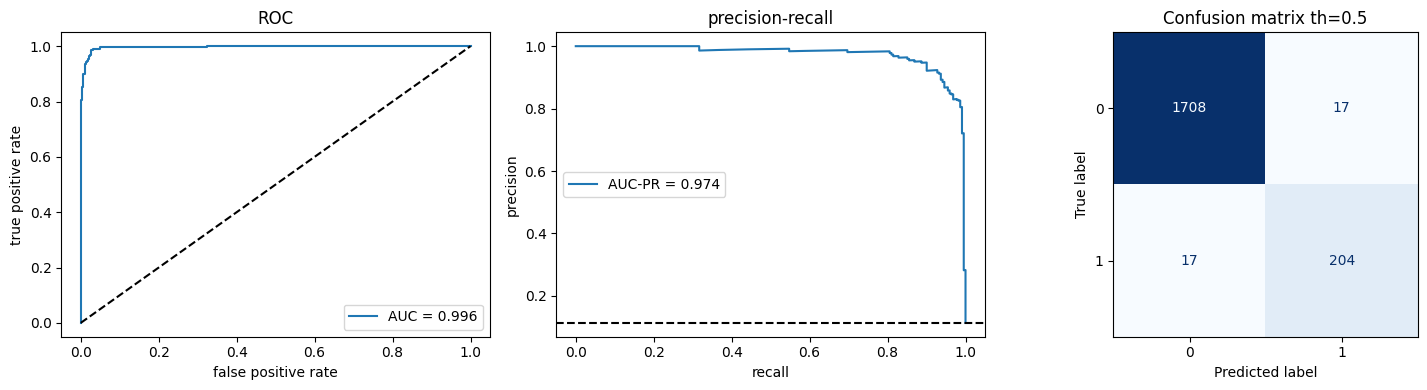

In [17]:
if RUN_FINAL:
    import matplotlib.pyplot as plt
    from sklearn.metrics import roc_curve, precision_recall_curve, ConfusionMatrixDisplay

    # ---- CSV con le predizioni ----
    # il test_loader non mescola (niente shuffle), quindi l'ordine delle predizioni
    # coincide con l'ordine di test_idx; ids ha lo stesso ordine del dataset
    test_ids = [ids[i] for i in test_idx.tolist()]

    df = pd.DataFrame({
        "UniprotID": test_ids,
        "true_class": y_test,
        "pred_class": y_pred,
        "score": p_ens,
    })
    df.to_csv(f"{OUT_DIR}/test_predictions.csv", index=False)

    
    # ---- grafici ----
    fig, ax = plt.subplots(1, 3, figsize=(15, 4))

    # (1) ROC
    fpr, tpr, _ = roc_curve(y_test, p_ens)
    ax[0].plot(fpr, tpr, label=f"AUC = {roc_auc_score(y_test, p_ens):.3f}")
    ax[0].plot([0, 1], [0, 1], "k--")
    ax[0].set_xlabel("false positive rate")
    ax[0].set_ylabel("true positive rate")
    ax[0].set_title("ROC")
    ax[0].legend()

    # (2) precision-recall
    prec, rec, _ = precision_recall_curve(y_test, p_ens)
    ax[1].plot(rec, prec, label=f"AUC-PR = {average_precision_score(y_test, p_ens):.3f}")
    ax[1].axhline(y_test.mean(), color="k", ls="--")      # livello casuale = frazione di positivi
    ax[1].set_xlabel("recall")
    ax[1].set_ylabel("precision")
    ax[1].set_title("precision-recall")
    ax[1].legend()

    # (3) matrice di confusione (soglia 0.5)
    ConfusionMatrixDisplay.from_predictions(y_test, y_pred, ax=ax[2], colorbar=False,cmap="Blues")
    ax[2].set_title("Confusion matrix th=0.5")
     

    plt.tight_layout()
    plt.show()

### Come ricaricare un modello salvato
```python
ckpt = torch.load(f"{OUT_DIR}/sigcnn_final_seed0.pt", map_location=device)
model = SigCNN(**ckpt["config"]).to(device)
model.load_state_dict(ckpt["state_dict"])
model.eval()
```